# Minha primeira LLM e conceitos basicos

Comecei estudando o básico de como um modelo de linguagem "lê" texto e terminei treinando um modelo meu, do zero, com um livro do Nietzsche.

Segui a aula do Prof. Marlon Ferrari no YouTube (LLM na Prática, com BERT) e fui adaptando do meu jeito.

Pra rodar: `pip install -r requirements.txt` e depois *Restart & Run All*. O livro é baixado sozinho.

In [1]:
import pandas as pd

### letra virando número

Rede neural não lê texto, só número. Então o primeiro passo é montar uma "cifra": cada letra ganha um número.

In [2]:
frase_base = 'o café da manhã esfriou na mesa'

# Quais simbolos únicos existem nessa frase?
simbolos = sorted(set(frase_base))
print('Símbolos encontrados:', simbolos)
print('Quantos símbolos o modelo conhece:', len(simbolos))

Símbolos encontrados: [' ', 'a', 'c', 'd', 'e', 'f', 'h', 'i', 'm', 'n', 'o', 'r', 's', 'u', 'ã', 'é']
Quantos símbolos o modelo conhece: 16


In [3]:
# Montando a "cifra": cada símbolo ganha um número
tabela_ida = {simbolo: posicao for posicao, simbolo in enumerate(simbolos)}
tabela_volta = {posicao: simbolo for posicao, simbolo in enumerate(simbolos)}

def codificar(texto):
    return [tabela_ida[s] for s in texto]

def decodificar(numeros):
    return ''.join(tabela_volta[n] for n in numeros)

In [4]:
teste1 = 'fome de manhã'
numeros = codificar(teste1)
print('Texto -> números:', numeros)
print('Números -> texto:', decodificar(numeros))

Texto -> números: [5, 10, 8, 4, 0, 3, 4, 0, 8, 1, 9, 6, 14]
Números -> texto: fome de manhã


### e se for palavra inteira?

Letra sozinha não quer dizer nada, então testei usar a palavra inteira (one-hot). Funciona, mas gera coluna demais e perde a ordem das palavras.

In [5]:
cardapio = pd.DataFrame({
    'pedido': [
        'quero um café com leite',
        'quero um suco de laranja',
        'hoje quero só um café',
    ]
})

# nesta etapa o modelo descobre todas as palavras diferentes e cria uma coluna para cada uma, 
# cada linha mostra quais palavras aquela frase usa

tabela_presenca = cardapio['pedido'].str.get_dummies(sep=' ')
tabela_presenca

,café,com,de,hoje,laranja,leite,quero,suco,só,um
0,1,1,0,0,0,1,1,0,0,1
1,0,0,1,0,1,0,1,1,0,1
2,1,0,0,1,0,0,1,0,1,1


### tokens, o meio-termo

É o que os LLMs de verdade usam: pedaços de palavra. Repara que o GPT-2 corta bem mais o português do que o inglês, porque foi treinado quase só com inglês.

In [6]:
# separar por letras: poucos símbolos, mas cada um sozinho não quer dizer nada
# separar por palavras: carregam significado, mas são símbolos demais, e qualquer palavra nova trava o modelo
import tiktoken

tokenizador_gpt = tiktoken.get_encoding('gpt2')

for frase in ['the coffee is hot', 'o café está quente', 'paralelepípedo']:
    ids = tokenizador_gpt.encode(frase)
    pedacos = [tokenizador_gpt.decode([i]) for i in ids]
    print(f'{frase!r}')
    print('   ids    :', ids)
    print('   pedaços:', pedacos)
    print('   tokens :', len(ids), '| letras:', len(frase))
    print()

'the coffee is hot'
   ids    : [1169, 6891, 318, 3024]
   pedaços: ['the', ' coffee', ' is', ' hot']
   tokens : 4 | letras: 17

'o café está quente'
   ids    : [78, 40304, 1556, 6557, 627, 21872]
   pedaços: ['o', ' café', ' est', 'á', ' qu', 'ente']
   tokens : 6 | letras: 18

'paralelepípedo'
   ids    : [1845, 1000, 293, 79, 8836, 9124, 78]
   pedaços: ['par', 'ale', 'le', 'p', 'í', 'ped', 'o']
   tokens : 7 | letras: 14



### o jogo do GPT e o jogo do BERT

O GPT aprende adivinhando a próxima palavra. O BERT aprende preenchendo uma lacuna no meio da frase, olhando pros dois lados. O modelo que eu treinei abaixo é do tipo BERT.

In [7]:
import random

frase_treino = 'o gato subiu no telhado para pegar o peixe'
palavras = frase_treino.split()

print('JOGO DO GPT: adivinhar a próxima palavra')
for fim in range(1, len(palavras)):
    contexto = palavras[:fim]
    resposta = palavras[fim]
    print(f'   vê: {" ".join(contexto):<40} -> deve chutar: {resposta}')

print()
print('JOGO DO BERT: preencher a lacuna')
for rodada in range(4):
    posicao = random.randrange(len(palavras))
    com_lacuna = palavras.copy()
    com_lacuna[posicao] = '<mask>'
    print(f'   vê: {" ".join(com_lacuna):<50} -> deve chutar: {palavras[posicao]}')

JOGO DO GPT: adivinhar a próxima palavra
   vê: o                                        -> deve chutar: gato
   vê: o gato                                   -> deve chutar: subiu
   vê: o gato subiu                             -> deve chutar: no
   vê: o gato subiu no                          -> deve chutar: telhado
   vê: o gato subiu no telhado                  -> deve chutar: para
   vê: o gato subiu no telhado para             -> deve chutar: pegar
   vê: o gato subiu no telhado para pegar       -> deve chutar: o
   vê: o gato subiu no telhado para pegar o     -> deve chutar: peixe

JOGO DO BERT: preencher a lacuna
   vê: o gato <mask> no telhado para pegar o peixe        -> deve chutar: subiu
   vê: o <mask> subiu no telhado para pegar o peixe       -> deve chutar: gato
   vê: o gato <mask> no telhado para pegar o peixe        -> deve chutar: subiu
   vê: o gato subiu no <mask> para pegar o peixe          -> deve chutar: telhado


---
## treinando a minha LLM
Daqui pra baixo eu treino um modelo do zero com o livro "Crepúsculo dos Ídolos" do Nietzsche.

### 1. baixando o livro

In [8]:
import os
import urllib.request

os.makedirs('dados', exist_ok=True)
arquivo_livro = 'dados/crepusculo.txt'

url_livro = 'https://raw.githubusercontent.com/ferrarimarlon/NietzscheLLM/main/crepusculoDosIdolos.txt'
urllib.request.urlretrieve(url_livro, arquivo_livro)

with open(arquivo_livro, encoding='utf-8') as f:
    livro = f.read().replace('\r\n', '\n')

# regravo o arquivo sem o \r do windows pra não sujar o tokenizer
with open(arquivo_livro, 'w', encoding='utf-8') as f:
    f.write(livro)

print('caracteres no livro:', len(livro))
print('palavras no livro  :', len(livro.split()))
print()
print(livro[:400])

caracteres no livro: 156690
palavras no livro  : 26107

a ociosidade é mãe de toda psicologia. como? seria a psicologia um... vício?
o mais corajoso dentre nós dispõe apenas raramente da coragem de afirmar aquilo que sabe verdadeiramente...
para viver só é necessário ser um animal ou então um deus — afirma aristóteles. falta o terceiro caso: é necessário ser um e outro, é necessário ser — filósofo...
"toda verdade é simples." — não existe aí uma dupla 


### 2. treinando o meu próprio tokenizer

Lembra que o GPT-2 picotou o português todo? Então aqui eu crio um tokenizer que aprende os pedaços de palavra direto do livro.

É o mesmo tipo do GPT-2 (Byte-Level BPE): ele começa com bytes soltos e vai juntando os pares que mais aparecem até virar sílaba, palavra...

No vídeo o vocabulário é de 52 mil, mas o livro é pequeno (umas 25 mil palavras), então 8 mil já sobra.

In [9]:
from tokenizers import ByteLevelBPETokenizer

tokenizador_nietzsche = ByteLevelBPETokenizer()

tokenizador_nietzsche.train(
    files=[arquivo_livro],
    vocab_size=8_000,
    min_frequency=2,  # só vira token o que aparece pelo menos 2 vezes
    special_tokens=['<s>', '<pad>', '</s>', '<unk>', '<mask>'],
)

print('tokens no vocabulário:', tokenizador_nietzsche.get_vocab_size())

tokens no vocabulário: 5008


Os tokens especiais são tipo "marcadores": `<s>` é começo de texto, `</s>` é fim, `<pad>` é enchimento pra deixar tudo do mesmo tamanho, `<unk>` é "não sei" e `<mask>` é a lacuna que o modelo vai tentar adivinhar.

Agora a comparação que eu queria ver: o meu tokenizer contra o do GPT-2, na mesma frase.

In [10]:
frase_teste = 'a verdade é uma mulher e o filósofo não sabe disso'

ids_meu = tokenizador_nietzsche.encode(frase_teste).ids
ids_gpt = tokenizador_gpt.encode(frase_teste)

print('meu tokenizer:', len(ids_meu), 'tokens')
print('  ', [tokenizador_nietzsche.decode([i]) for i in ids_meu])
print()
print('GPT-2        :', len(ids_gpt), 'tokens')
print('  ', [tokenizador_gpt.decode([i]) for i in ids_gpt])

meu tokenizer: 11 tokens
   ['a', ' verdade', ' é', ' uma', ' mulher', ' e', ' o', ' filósofo', ' não', ' sabe', ' disso']

GPT-2        : 21 tokens
   ['a', ' ver', 'd', 'ade', ' é', ' u', 'ma', ' mul', 'her', ' e', ' o', ' fil', 'ó', 'so', 'fo', ' n', 'ão', ' s', 'abe', ' dis', 'so']


Mesmo com um vocabulário 6x menor, o meu tokenizer corta o português bem melhor, porque aprendeu com texto em português.

Agora salvo ele numa pasta. Saem dois arquivos: `vocab.json` (a tabela token → número) e `merges.txt` (as regras de junção que ele aprendeu).

In [11]:
pasta_modelo = 'meu_modelo'
os.makedirs(pasta_modelo, exist_ok=True)

tokenizador_nietzsche.save_model(pasta_modelo)
print(os.listdir(pasta_modelo))

['checkpoints', 'config.json', 'merges.txt', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin', 'vocab.json']


### 3. carregando o tokenizer no formato do Hugging Face

A biblioteca `transformers` precisa do tokenizer num formato que ela conhece. Como o modelo vai ser um RoBERTa (a versão melhorada do BERT), uso o `RobertaTokenizer` lendo os arquivos que acabei de salvar.

In [12]:
from transformers import RobertaTokenizer

tokenizer = RobertaTokenizer.from_pretrained(pasta_modelo, model_max_length=128)

print(tokenizer('o homem é uma ponte')['input_ids'])
print('id do <mask>:', tokenizer.mask_token_id)

C:\Users\arthu\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[0, 83, 463, 306, 339, 3946, 2]
id do <mask>: 4


### 4. montando o cérebro (o modelo RoBERTa)

Aqui eu defino o tamanho da rede. O do vídeo é bem maior (6 camadas, 768 neurônios por camada). Diminuí pra conseguir treinar no meu computador sem GPU:

- `hidden_size`: tamanho do vetor que representa cada token
- `num_hidden_layers`: quantas camadas de Transformer empilhadas
- `num_attention_heads`: quantas "cabeças de atenção" cada camada tem (cada uma presta atenção numa relação diferente entre as palavras)
- `max_position_embeddings`: até quantos tokens ele aguenta ler de uma vez (128 + 2 que o RoBERTa reserva)

O modelo nasce com pesos aleatórios. Ou seja, por enquanto ele só chuta.

Fixo a semente antes de criar o modelo, assim os pesos aleatórios do começo são sempre os mesmos e o resultado dá pra reproduzir.

In [13]:
from transformers import set_seed

set_seed(42)

from transformers import RobertaConfig, RobertaForMaskedLM

configuracao = RobertaConfig(
    vocab_size=len(tokenizer),
    max_position_embeddings=130,
    hidden_size=256,
    num_hidden_layers=4,
    num_attention_heads=4,
    intermediate_size=1024,
    type_vocab_size=1,
)

modelo = RobertaForMaskedLM(config=configuracao)
print(f'parâmetros: {modelo.num_parameters():,}'.replace(',', '.'))

parâmetros: 4.546.448


Pra ter noção: o GPT-3 tem 175 bilhões de parâmetros. O meu tem uns poucos milhões. É um bebê, mas é meu.

### 5. preparando os dados de treino

O vídeo lê o livro linha por linha. Só que nesse arquivo tem "linhas" com mais de 5 mil caracteres, e tudo que passa de 128 tokens é jogado fora. Achei desperdício.

Então fiz diferente: transformo o livro inteiro em uma fila de tokens e corto em blocos de 128. Assim o modelo vê o livro todo.

In [14]:
ids_livro = tokenizer(livro, add_special_tokens=False)['input_ids']
print('tokens no livro inteiro:', len(ids_livro))

tamanho_bloco = 126  # +2 dos marcadores <s> e </s> = 128

blocos = []
for inicio in range(0, len(ids_livro) - tamanho_bloco + 1, tamanho_bloco):
    pedaco = ids_livro[inicio:inicio + tamanho_bloco]
    blocos.append({'input_ids': [tokenizer.bos_token_id] + pedaco + [tokenizer.eos_token_id]})

print('blocos de treino:', len(blocos))
print()
print('exemplo de bloco:')
print(tokenizer.decode(blocos[3]['input_ids']))

tokens no livro inteiro: 35570
blocos de treino: 282

exemplo de bloco:
<s> exemplo — são menos compreendidos que aqueles que são conformes sua época, mas escutamo-los melhor. que eu me exprima mais precisamente ainda: jamais somos compreendidos — e é disso que advém nossa autoridade...
entre mulheres. — "a verdade? oh, não conheces a verdade! não é ela um atentado contra nosso pudor?"
eis um artista como os aprecio. é modesto em suas necessidades: requer, em suma, somente duas coisas. seu pão e sua arte — panem et circen...
aquele que não sabe dispor sua vontade nas coisas quer ao menos atribuir-</s>


### 6. separando uma parte do livro pra prova

Se eu testar o modelo com o mesmo texto que ele leu, não tenho como saber se ele aprendeu ou só decorou.

Então guardo os últimos 10% do livro como **validação**: o modelo nunca treina nesses blocos, eles servem só pra prova. Pego blocos seguidos, do fim, em vez de sortear, porque blocos vizinhos têm frases parecidas e um sorteio deixaria o modelo "colar" na prova.

Um detalhe honesto: o tokenizer foi treinado com o livro inteiro, então ele conhece o vocabulário da validação. O modelo, não: o texto da validação ele nunca vê.

In [15]:
corte = int(len(blocos) * 0.9)
blocos_treino = blocos[:corte]
blocos_val = blocos[corte:]

print('blocos de treino   :', len(blocos_treino))
print('blocos de validação:', len(blocos_val))

blocos de treino   : 253
blocos de validação: 29


### 7. o "professor" que esconde palavras

O `DataCollatorForLanguageModeling` monta os lotes de treino e faz o jogo do BERT sozinho: em cada bloco ele esconde 15% dos tokens com `<mask>` e o modelo tem que adivinhar o que estava ali.

O legal é que a cada rodada ele sorteia lacunas diferentes, então o mesmo trecho vira um exercício novo toda vez.

In [16]:
from transformers import DataCollatorForLanguageModeling

coletor = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=True,
    mlm_probability=0.15,
)

# só pra ver o que ele faz com um bloco
amostra = coletor([blocos[3]])
print(tokenizer.decode(amostra['input_ids'][0]))

<s> exemplo — são menos compreendidos que aqueles que são conformes<mask> época, mas escutamo-los melhor. que eu me exprima mais precisamente ainda: jamais somos<mask> — e é disso queguevém nossa<mask>...
entre mulheres.<mask> "a verdade? oh, não conheces a verdade!<mask> é ela um atentado contra nosso pudor?"<mask>eis um artista como os apre<mask>. é modesto em<mask> necessidades: requer, em suma<mask> somente duas<mask>. seu pão e sua arte — panem et circen...
dio que não sabe dispor<mask> vontade nas coisas quer ao<mask> atribuir-</s>


A prova precisa ser sempre a mesma. O coletor sorteia lacunas novas toda vez, então se eu usasse ele na validação, cada prova teria lacunas diferentes e as notas não dariam pra comparar.

Por isso sorteio as lacunas da validação **uma vez só**, com semente fixa, e guardo. No treino continua sorteando lacunas novas a cada rodada.

In [17]:
import torch

torch.manual_seed(0)
validacao_fixa = []
for bloco in blocos_val:
    lote = coletor([bloco])
    validacao_fixa.append({
        'input_ids': lote['input_ids'][0].tolist(),
        'labels': lote['labels'][0].tolist(),
    })

def montar_lote(exemplos):
    # validação já vem com as lacunas prontas; treino sorteia lacunas novas
    if 'labels' in exemplos[0]:
        return {chave: torch.tensor([e[chave] for e in exemplos]) for chave in ('input_ids', 'labels')}
    return coletor(exemplos)

lacunas_val = sum(sum(1 for r in e['labels'] if r != -100) for e in validacao_fixa)
print('lacunas na prova de validação:', lacunas_val)

lacunas na prova de validação: 584


### 8. treinando (agora com prova)

Cada época é o modelo lendo o trecho de treino inteiro uma vez. O vídeo usa 1200 épocas, o que no CPU levaria uma eternidade.

Na primeira versão deste notebook eu treinei 100 + 200 épocas e só olhava o `loss` de treino. Só que o loss de treino é o modelo corrigindo a própria lição de casa: ele sempre cai, mesmo quando o modelo está só decorando.

Agora, a cada 100 passos, ele faz a prova de validação (`eval_loss`):

- os dois caindo juntos: está aprendendo
- treino caindo e validação subindo: parou de aprender e começou a decorar

Coloquei 300 épocas como teto e um **early stopping**: se a validação piorar 5 provas seguidas, o treino para sozinho e eu fico com a versão que foi melhor na prova.

No CPU leva uns 40 minutos, então é hora do café.

In [18]:
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback

print('GPU disponível?', torch.cuda.is_available())

EPOCAS = 300  # teto: o early stopping pode parar antes

argumentos = TrainingArguments(
    output_dir=os.path.join(pasta_modelo, 'checkpoints'),
    num_train_epochs=EPOCAS,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=5e-4,
    warmup_steps=100,
    logging_steps=100,
    eval_strategy='steps',
    eval_steps=100,
    save_strategy='steps',
    save_steps=100,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,
    report_to='none',
    seed=42,
)

treinador = Trainer(
    model=modelo,
    args=argumentos,
    data_collator=montar_lote,
    train_dataset=blocos_treino,
    eval_dataset=validacao_fixa,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=5)],
)

GPU disponível? False


In [19]:
treinador.train()

Step,Training Loss,Validation Loss
100,7.383085,6.835598
200,6.538892,6.691610
300,6.290884,6.625813
400,6.077091,6.608704
500,5.896182,6.577327
600,5.700932,6.602756
700,5.520938,6.581086
800,5.354875,6.674457
900,5.188453,6.734106
1000,5.038354,6.764438


TrainOutput(global_step=1000, training_loss=5.89896875, metrics={'train_runtime': 486.6628, 'train_samples_per_second': 32.492, 'train_steps_per_second': 2.055, 'total_flos': 39239334371328.0, 'train_loss': 5.89896875, 'epoch': 62.5})

In [20]:
# salvando o modelo treinado junto com o tokenizer
treinador.save_model(pasta_modelo)
tokenizer.save_pretrained(pasta_modelo)
print(os.listdir(pasta_modelo))

['checkpoints', 'config.json', 'merges.txt', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin', 'vocab.json']


### 9. o boletim

Primeiro o gráfico das duas curvas. A linha tracejada marca a versão que foi melhor na prova, que é a que ficou salva.

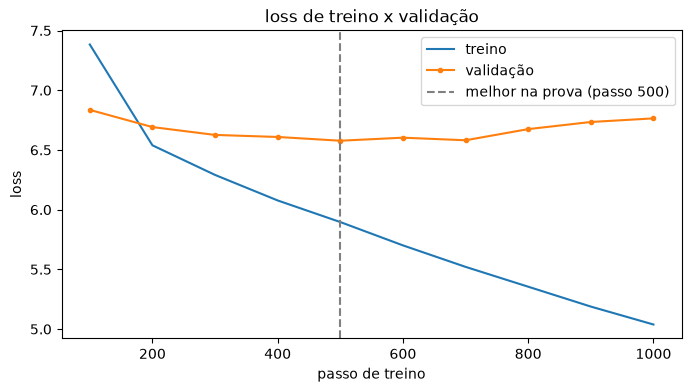

In [21]:
import math
import matplotlib.pyplot as plt

historico = treinador.state.log_history
curva_treino = [(h['step'], h['loss']) for h in historico if 'loss' in h]
curva_val = [(h['step'], h['eval_loss']) for h in historico if 'eval_loss' in h]
melhor_passo = int(treinador.state.best_model_checkpoint.rstrip('/').split('-')[-1])

plt.figure(figsize=(8, 4))
plt.plot(*zip(*curva_treino), label='treino')
plt.plot(*zip(*curva_val), label='validação', marker='o', markersize=3)
plt.axvline(melhor_passo, color='gray', linestyle='--', label=f'melhor na prova (passo {melhor_passo})')
plt.xlabel('passo de treino')
plt.ylabel('loss')
plt.title('loss de treino x validação')
plt.legend()
plt.show()

Um loss sozinho não diz se o modelo é bom ou ruim. Ele precisa de comparação. Então coloco o modelo contra dois chutes bobos, nas mesmas lacunas da validação:

- **chute aleatório**: qualquer token do vocabulário com a mesma chance
- **chute pela frequência**: chuta mais as palavras que mais aparecem no livro ("a", "o", "que"...), sem olhar a frase

Se o modelo não ganhar do chute pela frequência, ele não aprendeu nada além de "palavra comum".

Também mostro a **perplexidade**, que é só `e` elevado ao loss. Ela é mais fácil de ler: perplexidade 50 é como se o modelo estivesse em dúvida entre 50 tokens em cada lacuna.

In [22]:
from collections import Counter

# chute pela frequência: conta os tokens do trecho de treino (sem <s> e </s>)
contagem = Counter(t for b in blocos_treino for t in b['input_ids'][1:-1])
total = sum(contagem.values())
V = len(tokenizer)

def chance_pela_frequencia(token_id):
    return (contagem[token_id] + 1) / (total + V)  # +1 pra nenhum token ficar com chance zero

mais_frequentes = [t for t, _ in contagem.most_common(5)]

modelo_final = treinador.model
modelo_final.eval()

perda_modelo = perda_freq = 0.0
acertos = Counter()
n = 0

with torch.no_grad():
    for exemplo in validacao_fixa:
        entrada = torch.tensor([exemplo['input_ids']], device=modelo_final.device)
        logits = modelo_final(entrada).logits[0]
        for posicao, certo in enumerate(exemplo['labels']):
            if certo == -100:
                continue  # não é lacuna
            log_chances = logits[posicao].log_softmax(-1)
            top5 = log_chances.topk(5).indices.tolist()

            perda_modelo -= log_chances[certo].item()
            perda_freq -= math.log(chance_pela_frequencia(certo))
            acertos['modelo top-1'] += top5[0] == certo
            acertos['modelo top-5'] += certo in top5
            acertos['freq top-1'] += mais_frequentes[0] == certo
            acertos['freq top-5'] += certo in mais_frequentes
            n += 1

loss_treino_final = curva_treino[-1][1]
loss_val = perda_modelo / n

boletim = pd.DataFrame({
    'loss': [loss_val, perda_freq / n, math.log(V)],
    'perplexidade': [math.exp(loss_val), math.exp(perda_freq / n), V],
    'acerto top-1': [acertos['modelo top-1'] / n, acertos['freq top-1'] / n, 1 / V],
    'acerto top-5': [acertos['modelo top-5'] / n, acertos['freq top-5'] / n, 5 / V],
}, index=['meu modelo', 'chute pela frequência', 'chute aleatório'])

print(f'lacunas avaliadas: {n}')
print(f'loss de treino no fim: {loss_treino_final:.2f} | loss de validação: {loss_val:.2f}')
print(f'diferença (quanto ele decorou): {loss_val - loss_treino_final:.2f}')
boletim.round(3)

lacunas avaliadas: 584
loss de treino no fim: 5.04 | loss de validação: 6.58
diferença (quanto ele decorou): 1.54


,loss,perplexidade,acerto top-1,acerto top-5
meu modelo,6.582,722.175,0.106,0.192
chute pela frequência,6.769,870.171,0.070,0.152
chute aleatório,8.519,5008.000,0.000,0.001


Como eu leio essa tabela:

- **meu modelo contra chute pela frequência**: é o quanto ele aprendeu de verdade sobre o contexto das frases
- **loss de treino contra loss de validação**: quanto maior a diferença, mais ele decorou em vez de aprender. Com um livro só, é esperado que ele decore bastante

O que deu no meu treino:

- **a validação parou de melhorar no passo 500** (época ~31). Daí pra frente o loss de treino continuou caindo (5,9 → 5,0) e o de validação subiu (6,58 → 6,76). Ele começou a decorar, e o early stopping cortou no passo 1000 e guardou a versão do passo 500.
- **no texto que nunca viu, ele ganha do chute pela frequência, mas por pouco**: perplexidade 722 contra 870, e acerta o primeiro chute em 10,6% das lacunas contra 7,0%.
- **por isso os chutes nas frases são quase sempre "," e "de"**: com um livro só, o que ele aprende e funciona fora do treino é principalmente quais palavras são comuns.

A versão antiga deste notebook chegava a loss 1,3 no treino e parecia ótima. Agora eu sei que aquilo era ele decorando o livro: sem a prova separada, eu nunca teria percebido.

### 10. a hora da verdade

Agora eu escrevo uma frase com `<mask>` e o modelo me diz o que ele acha que vai ali, com a porcentagem de certeza.

Primeiro tentei com o `pipeline` do Hugging Face, mas ele se enrolava com o espaço antes do `<mask>` e o modelo ficava chutando pedaço de palavra. Aí montei a frase na mão, do mesmo jeito que o modelo viu no treino.

Detalhe: o livro está todo em minúsculo, então escrevo as frases em minúsculo também.

In [23]:
import torch

modelo_treinado = treinador.model
modelo_treinado.eval()  # modo de teste, desliga as partes que só servem pro treino

def perguntar(frase, quantos=5):
    print(frase)
    antes, depois = frase.split('<mask>')

    # monto a frase na mão: <s> + texto antes + <mask> + texto depois + </s>
    ids = ([tokenizer.bos_token_id]
           + tokenizer.encode(antes.rstrip(), add_special_tokens=False)
           + [tokenizer.mask_token_id]
           + tokenizer.encode(depois, add_special_tokens=False)
           + [tokenizer.eos_token_id])
    posicao_lacuna = ids.index(tokenizer.mask_token_id)

    with torch.no_grad():
        entrada = torch.tensor([ids], device=modelo_treinado.device)
        notas = modelo_treinado(entrada).logits[0, posicao_lacuna]

    chances = notas.softmax(dim=-1)
    melhores = chances.topk(quantos)
    for chance, token_id in zip(melhores.values, melhores.indices):
        palavra = tokenizer.decode([int(token_id)]).strip()
        print(f'   {palavra:<15} {chance.item():.1%}')
    print()

In [24]:
# essa frase está no livro. em que parte? se for nos primeiros 90%, o modelo treinou nela
trecho = 'o que não me faz morrer me torna mais forte'
posicao = livro.find(trecho)
if posicao == -1:
    print('não achei a frase exata no livro')
else:
    parte = 'treino' if posicao / len(livro) < 0.9 else 'validação'
    print(f'a frase está em {posicao / len(livro):.0%} do livro, na parte de {parte}')
print()

perguntar('o que não me faz morrer me torna mais <mask>.')

# essas eu inventei
perguntar('a moral é uma invenção dos <mask>.')
perguntar('o filósofo não tem <mask>.')
perguntar('deus é um <mask> do homem.')

a frase está em 1% do livro, na parte de treino

o que não me faz morrer me torna mais <mask>.
   ,               2.5%
   de              2.4%
   uma             2.1%
   o               1.9%
   por             1.8%

a moral é uma invenção dos <mask>.
   ,               6.9%
   que             3.8%
   não             3.4%
   o               3.3%
   a               3.3%

o filósofo não tem <mask>.
   ,               5.1%
   a               4.7%
   de              1.9%
   .               1.9%
   como            1.6%

deus é um <mask> do homem.
   ,               6.4%
   e               3.9%
   a               3.0%
   .               2.6%
   -               2.4%



Brinca à vontade aqui embaixo, é só trocar a frase:

In [25]:
perguntar('a verdade é <mask>.')

a verdade é <mask>.
   ,               6.7%
   e               5.5%
   a               3.0%
   o               3.0%
   .               2.9%



---
### o que eu aprendi com isso

O modelo não "entende" Nietzsche. Ele aprendeu quais pedaços de palavra costumam aparecer perto de quais.

Na primeira versão deste notebook eu só olhava o loss de treino e achava que estava indo bem. Separando um pedaço do livro que o modelo nunca viu, deu pra medir de verdade: o boletim compara o modelo com dois chutes bobos, e a distância entre o loss de treino e o de validação mostra o quanto ele decorou. Essa foi a maior lição: **sem uma prova separada, não dá pra saber se o modelo aprendeu.**

Nos testes com frases dá pra ver o limite dele: quase todo chute é "," ou "de". Nem o "forte", numa frase que estava no treino, apareceu. Com 26 mil palavras não tem texto suficiente pra ele aprender o sentido das frases sem decorar.

Tudo isso com 4,5 milhões de parâmetros, um livro de 26 mil palavras e uns 40 minutos de treino no meu PC, sem GPU. Os modelos grandes fazem a mesma coisa, só que com bilhões de parâmetros e uma quantidade absurda de texto.

O que mais me pegou foi o tokenizer. Antes eu achava que o modelo lia palavra por palavra. Na verdade ele lê pedaços, e quem decide esses pedaços é treinado antes do modelo. Até o espaço antes de uma palavra faz diferença, como eu descobri apanhando no teste.

Próximo passo: treinar com mais livros (pra ele decorar menos) e testar um modelo tipo GPT, que gera texto em vez de só preencher lacuna.

Aula que eu segui: [LLM na Prática, Prof. Marlon Ferrari](https://www.youtube.com/watch?v=LphBQB1amrw)